# Parents Waiting for Speech and Language Therapy (SaLT)


In [8]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown



## 1. Import the data

In [9]:
#Loading the data
df = pd.read_csv("../data/parentwaiting.csv", encoding="utf-8")
df.head()

,Which stakeholder are you?,"Is your child currently receiving, waiting for, or has previously received Speech and Language Therapy (SaLT)?","Who, in relation to the child, is filling out this questionnaire? - Selected Choice",Where are you based? - Selected Choice,What is your work status? - Selected Choice,How old is your child?,Has your child received any of the following diagnoses? (select all that apply) - Selected Choice,How long has your child been on the waiting list for SaLT?,"How do you agree with the statement: I feel emotionally supported in managing my child's speech, language and communication needs while waiting for Speech and Language Therapy (SaLT).","While waiting, what support (if any) has your family sought or received? - Selected Choice","While waiting, what support (if any) has your family sought or received? - Other (please specify) - Text","Roughly, how much has your family spent out of pocket per month trying to support your child while waiting?","While waiting for SaLT, what would have made the biggest difference to your family? - Selected Choice","While waiting for SaLT, what would have made the biggest difference to your family? - Other (please specify) - Text",How has the wait affected your child or your family?,"Finally, would you be interested in having a quick chat to help us improve our research? - Selected Choice",Unnamed: 16
0,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Full-time,5-10,"Speech, language and communication needs (SLCN...",More than 2 years,Strongly disagree,Apps or digital tools,\n,£300–£600,"A clear estimate of when the wait would end,Ac...",\n,I feel my child could be progressing quicker w...,No,NaN
1,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Self-employed,0-5,NaN,1-2 years,Strongly disagree,Other (please specify),I funded aba for a year,Over £600,Activities or exercises we could do at home in...,\n,Worries abour a child,Yes (please provide your email address),NaN
2,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Part-time,5-11,Autism / Autism Spectrum Condition (confirmed)...,Less than 12 weeks,Disagree,Books or self-purchased materials,\n,£0 — we haven't paid for anything,Activities or exercises we could do at home in...,\n,Our experience is obtaining a SALT assessment ...,No,NaN
3,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Other,11-16,Autism / Autism Spectrum Condition (confirmed)...,More than 2 years,Strongly disagree,Parent support groups (online or in person),\n,Over £600,Activities or exercises we could do at home in...,\n,Six years of delayed therapies including SLT h...,Yes (please provide your email address),NaN
4,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,"Scotland, Wales, or Northern Ireland",Self-employed,\n,\n,\n,\n,\n,\n,\n,\n,\n,\n,\n,NaN


## 2. Clean the Qualtrics export

In [10]:
def clean_cell(value):
    """Convert whitespace-only and escaped-newline cells to missing values."""
    if pd.isna(value):
        return np.nan
    if isinstance(value, str):
        value = value.replace("\n", " ").replace("\r", " ").strip()
        value = re.sub(r"\s+", " ", value)
        if value == "":
            return np.nan
    return value

# Clean values and remove completely empty / unnamed columns
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.str.match(r"^Unnamed", na=False)]

# Remove exact duplicate rows, while reporting whether any were found
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate response(s).")
print(f"Clean dataset: {df.shape[0]} responses × {df.shape[1]} columns")

# Assign anonymous participant IDs for quotations and audit trails
df.insert(0, "Participant_ID", [f"PW{i+1:02d}" for i in range(len(df))])

display(df.head())

Removed 0 duplicate response(s).
Clean dataset: 6 responses × 16 columns


,Participant_ID,Which stakeholder are you?,"Is your child currently receiving, waiting for, or has previously received Speech and Language Therapy (SaLT)?","Who, in relation to the child, is filling out this questionnaire? - Selected Choice",Where are you based? - Selected Choice,What is your work status? - Selected Choice,How old is your child?,Has your child received any of the following diagnoses? (select all that apply) - Selected Choice,How long has your child been on the waiting list for SaLT?,"How do you agree with the statement: I feel emotionally supported in managing my child's speech, language and communication needs while waiting for Speech and Language Therapy (SaLT).","While waiting, what support (if any) has your family sought or received? - Selected Choice","While waiting, what support (if any) has your family sought or received? - Other (please specify) - Text","Roughly, how much has your family spent out of pocket per month trying to support your child while waiting?","While waiting for SaLT, what would have made the biggest difference to your family? - Selected Choice","While waiting for SaLT, what would have made the biggest difference to your family? - Other (please specify) - Text",How has the wait affected your child or your family?,"Finally, would you be interested in having a quick chat to help us improve our research? - Selected Choice"
0,PW01,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Full-time,5-10,"Speech, language and communication needs (SLCN...",More than 2 years,Strongly disagree,Apps or digital tools,\n,£300–£600,"A clear estimate of when the wait would end,Ac...",\n,I feel my child could be progressing quicker w...,No
1,PW02,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Self-employed,0-5,NaN,1-2 years,Strongly disagree,Other (please specify),I funded aba for a year,Over £600,Activities or exercises we could do at home in...,\n,Worries abour a child,Yes (please provide your email address)
2,PW03,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Part-time,5-11,Autism / Autism Spectrum Condition (confirmed)...,Less than 12 weeks,Disagree,Books or self-purchased materials,\n,£0 — we haven't paid for anything,Activities or exercises we could do at home in...,\n,Our experience is obtaining a SALT assessment ...,No
3,PW04,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,Rest of England,Other,11-16,Autism / Autism Spectrum Condition (confirmed)...,More than 2 years,Strongly disagree,Parent support groups (online or in person),\n,Over £600,Activities or exercises we could do at home in...,\n,Six years of delayed therapies including SLT h...,Yes (please provide your email address)
4,PW05,Parent or Caregiver,Yes — on a waiting list for SaLT,Mother,"Scotland, Wales, or Northern Ireland",Self-employed,\n,\n,\n,\n,\n,\n,\n,\n,\n,\n,\n


### Missing data overview

In [11]:
missing = pd.DataFrame({
    "Non-missing responses": df.notna().sum(),
    "Missing responses": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(1)
}).sort_values("Missing (%)", ascending=False)
display(missing)

,Non-missing responses,Missing responses,Missing (%)
Has your child received any of the following diagnoses? (select all that apply) - Selected Choice,5,1,16.7
Participant_ID,6,0,0.0
"How do you agree with the statement: I feel emotionally supported in managing my child's speech, language and communication needs while waiting for Speech and Language Therapy (SaLT).",6,0,0.0
How has the wait affected your child or your family?,6,0,0.0
"While waiting for SaLT, what would have made the biggest difference to your family? - Other (please specify) - Text",6,0,0.0
"While waiting for SaLT, what would have made the biggest difference to your family? - Selected Choice",6,0,0.0
"Roughly, how much has your family spent out of pocket per month trying to support your child while waiting?",6,0,0.0
"While waiting, what support (if any) has your family sought or received? - Other (please specify) - Text",6,0,0.0
"While waiting, what support (if any) has your family sought or received? - Selected Choice",6,0,0.0
How long has your child been on the waiting list for SaLT?,6,0,0.0


## 3. Identify survey questions

In [12]:
def find_col(keyword):
    matches = [c for c in df.columns if keyword.lower() in c.lower()]
    if not matches:
        raise KeyError(f"No column found containing: {keyword}")
    return matches[0]

COL = {
    "relationship": find_col("relation to the child"),
    "region": find_col("Where are you based"),
    "work": find_col("work status"),
    "age": find_col("How old is your child"),
    "diagnoses": find_col("following diagnoses"),
    "wait": find_col("How long has your child been on the waiting list"),
    "emotional": find_col("feel emotionally supported"),
    "support": find_col("what support (if any) has your family sought or received? - Selected"),
    "support_other": find_col("what support (if any) has your family sought or received? - Other"),
    "spend": find_col("spent out of pocket per month"),
    "difference": find_col("made the biggest difference to your family? - Selected"),
    "impact": find_col("How has the wait affected"),
    "interview": find_col("interested in having a quick chat"),
}

for short_name, full_name in COL.items():
    print(f"{short_name:16s} -> {full_name}")

relationship     -> Who, in relation to the child, is filling out this questionnaire? - Selected Choice
region           -> Where are you based? - Selected Choice
work             -> What is your work status? - Selected Choice
age              -> How old is your child?
diagnoses        -> Has your child received any of the following diagnoses? (select all that apply) - Selected Choice
wait             -> How long has your child been on the waiting list for SaLT?
emotional        -> How do you agree with the statement: I feel emotionally supported in managing my child's speech, language and communication needs while waiting for Speech and Language Therapy (SaLT).
support          -> While waiting, what support (if any) has your family sought or received? - Selected Choice
support_other    -> While waiting, what support (if any) has your family sought or received? - Other (please specify) - Text
spend            -> Roughly, how much has your family spent out of pocket per month trying to

## 4. Helper functions

In [13]:
def frequency_table(series, include_missing=False):
    """Return counts and percentages using valid responses as denominator."""
    s = series.copy()
    if include_missing:
        s = s.fillna("Missing")
    else:
        s = s.dropna()
    counts = s.value_counts(dropna=False)
    denominator = counts.sum()
    out = pd.DataFrame({"Count": counts})
    out["Percent"] = (out["Count"] / denominator * 100).round(1)
    out.index.name = "Response"
    return out.reset_index()


def plot_frequency(series, title, order=None, filename=None):
    """Horizontal bar chart with count and valid-response percentage labels."""
    s = series.dropna()
    if s.empty:
        print(f"No valid responses for: {title}")
        return
    counts = s.value_counts()
    if order:
        counts = counts.reindex([x for x in order if x in counts.index]).dropna()
    perc = counts / len(s) * 100

    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.55 * len(counts) + 1)))
    bars = ax.barh(counts.index.astype(str), counts.values)
    ax.invert_yaxis()
    ax.set_xlabel("Number of respondents")
    ax.set_title(title)
    ax.set_xlim(0, max(counts.max() * 1.3, 1))
    ax.grid(axis="x", alpha=0.25)
    for bar, count, pct in zip(bars, counts.values, perc.values):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f"{int(count)} ({pct:.0f}%)", va="center")
    plt.tight_layout()
    if filename:
        plt.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


def split_multiselect(series, delimiter=","):
    """Explode comma-separated Qualtrics multi-select responses."""
    return (
        series.dropna().astype(str)
        .str.split(delimiter)
        .explode()
        .str.strip()
        .replace("", np.nan)
        .dropna()
    )


def multiselect_table(series):
    exploded = split_multiselect(series)
    counts = exploded.value_counts()
    valid_respondents = series.notna().sum()
    out = pd.DataFrame({"Count": counts})
    out["Percent of valid respondents"] = (
        out["Count"] / valid_respondents * 100
    ).round(1) if valid_respondents else np.nan
    out.index.name = "Option"
    return out.reset_index()


def plot_multiselect(series, title, filename=None):
    tab = multiselect_table(series)
    if tab.empty:
        print(f"No valid responses for: {title}")
        return
    tab = tab.sort_values("Count", ascending=True)
    fig, ax = plt.subplots(figsize=(10, max(4, 0.62 * len(tab) + 1)))
    bars = ax.barh(tab["Option"], tab["Count"])
    ax.set_xlabel("Number of respondents selecting option")
    ax.set_title(title)
    ax.set_xlim(0, max(tab["Count"].max() * 1.35, 1))
    ax.grid(axis="x", alpha=0.25)
    for bar, count, pct in zip(bars, tab["Count"], tab["Percent of valid respondents"]):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f"{int(count)} ({pct:.0f}%)", va="center")
    plt.tight_layout()
    if filename:
        plt.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

## 5. Sample overview

Total eligible waiting-list parent/carer responses: n = 6


### Relationship to child

,Response,Count,Percent
0,Mother,6,100.0


NameError: name 'OUTPUT_DIR' is not defined

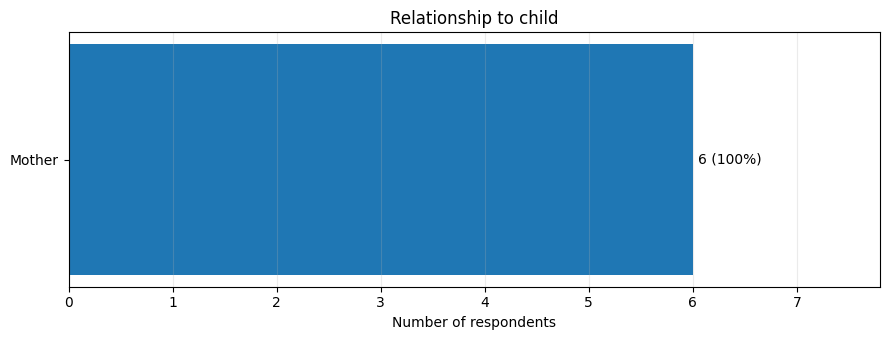

In [14]:
N = len(df)
print(f"Total eligible waiting-list parent/carer responses: n = {N}")

for label, key in [
    ("Relationship to child", "relationship"),
    ("Region", "region"),
    ("Work status", "work"),
    ("Child age group", "age")
]:
    display(Markdown(f"### {label}"))
    display(frequency_table(df[COL[key]]))
    plot_frequency(df[COL[key]], label, filename=f"{key}.png")

## 6. Diagnoses and neurodevelopmental characteristics

,Option,Count,Percent of valid respondents
0,Speech,2,66.7
1,language and communication needs (SLCN) — without an autism or learning disability diagnosis,2,66.7
2,Autism / Autism Spectrum Condition (confirmed),2,66.7
3,Other neurodevelopmental condition (e.g. ADHD,2,66.7
4,Developmental Language Disorder),2,66.7
5,Currently in assessment for autism or a learning disability,1,33.3


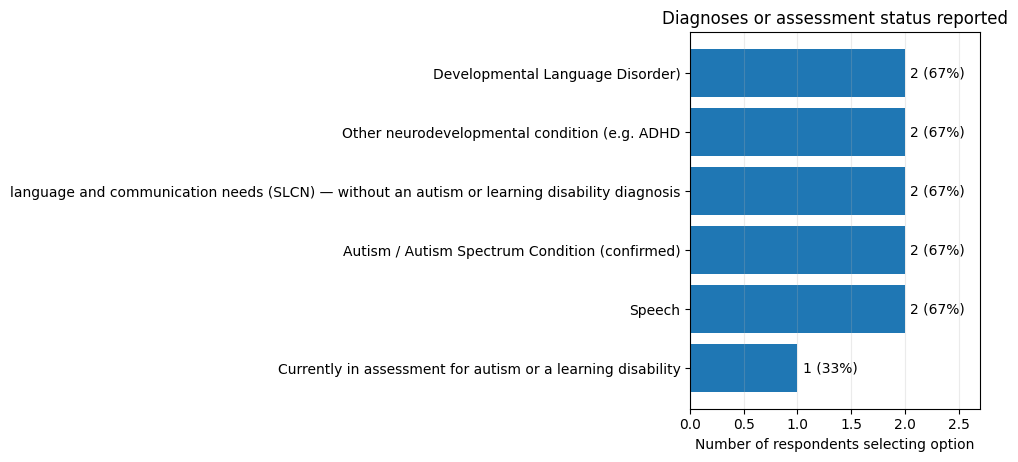

Percentages may sum to more than 100% because respondents could select multiple options.


In [ ]:
diagnosis_table = multiselect_table(df[COL["diagnoses"]])
display(diagnosis_table)
plot_multiselect(
    df[COL["diagnoses"]],
    "Diagnoses or assessment status reported",
    filename="diagnoses_multiselect.png"
)

print("Percentages may sum to more than 100% because respondents could select multiple options.")

## 7. Waiting-list duration

,Response,Count,Percent
0,More than 2 years,2,40.0
1,Less than 12 weeks,2,40.0
2,1-2 years,1,20.0


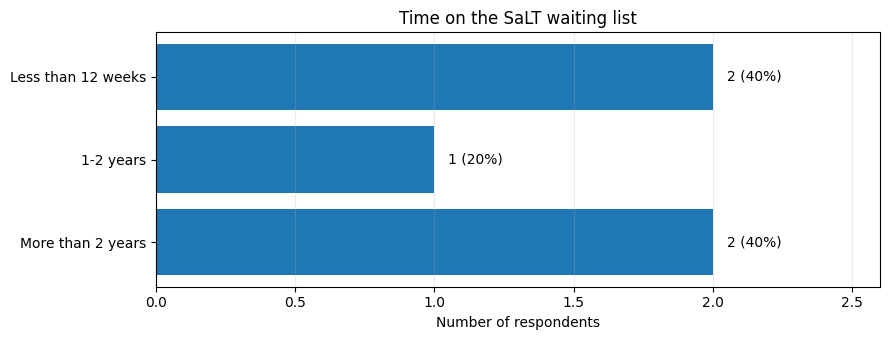

In [ ]:
WAIT_ORDER = [
    "Less than 12 weeks", "3-6 months", "6-12 months",
    "1-2 years", "More than 2 years"
]
wait_table = frequency_table(df[COL["wait"]])
display(wait_table)
plot_frequency(
    df[COL["wait"]],
    "Time on the SaLT waiting list",
    order=WAIT_ORDER,
    filename="waiting_time.png"
)

## 8. Perceived emotional support while waiting

,Response,Count,Percent
0,Strongly disagree,4,80.0
1,Disagree,1,20.0


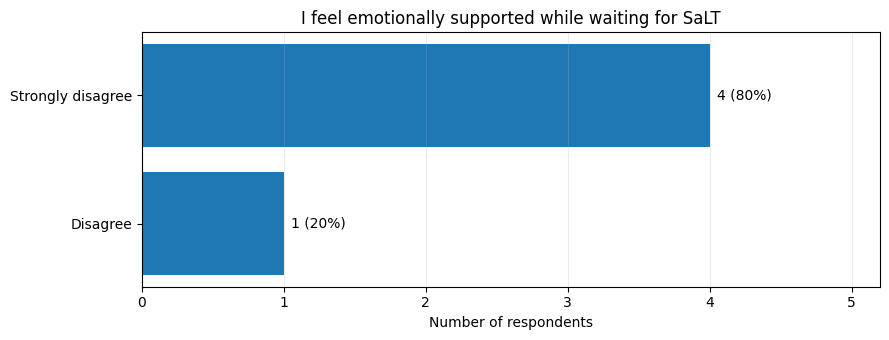

Valid responses: 5
Median Likert score: 1.0 / 5
Mean Likert score: 1.20 / 5
Disagreed/strongly disagreed: 5 of 5 (100.0%)
For a small sample, the median and response distribution should be prioritised over the mean.


In [ ]:
LIKERT_MAP = {
    "Strongly disagree": 1,
    "Disagree": 2,
    "Neither agree nor disagree": 3,
    "Agree": 4,
    "Strongly agree": 5,
}
LIKERT_ORDER = list(LIKERT_MAP.keys())

emotional = df[COL["emotional"]]
emotional_numeric = emotional.map(LIKERT_MAP)

emotional_table = frequency_table(emotional)
display(emotional_table)
plot_frequency(
    emotional,
    "I feel emotionally supported while waiting for SaLT",
    order=LIKERT_ORDER,
    filename="emotional_support.png"
)

valid_n = emotional_numeric.notna().sum()
if valid_n:
    print(f"Valid responses: {valid_n}")
    print(f"Median Likert score: {emotional_numeric.median():.1f} / 5")
    print(f"Mean Likert score: {emotional_numeric.mean():.2f} / 5")
    unsupported = emotional.isin(["Strongly disagree", "Disagree"]).sum()
    print(f"Disagreed/strongly disagreed: {unsupported} of {valid_n} ({unsupported/valid_n*100:.1f}%)")

print("For a small sample, the median and response distribution should be prioritised over the mean.")

## 9. Support sought or received while waiting

,Option,Count,Percent of valid respondents
0,Apps or digital tools,1,20.0
1,Other (please specify),1,20.0
2,Books or self-purchased materials,1,20.0
3,Parent support groups (online or in person),1,20.0
4,Private SaLT sessions (paid out of pocket),1,20.0


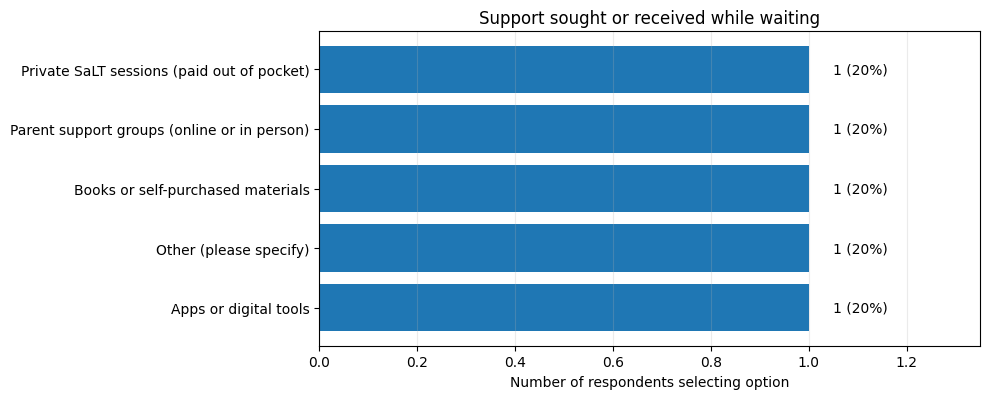

### Other support specified

,Participant_ID,Other support
1,PW02,I funded aba for a year


In [ ]:
support_table = multiselect_table(df[COL["support"]])
display(support_table)
plot_multiselect(
    df[COL["support"]],
    "Support sought or received while waiting",
    filename="support_received.png"
)

other_support = df.loc[df[COL["support_other"]].notna(), ["Participant_ID", COL["support_other"]]]
if not other_support.empty:
    display(Markdown("### Other support specified"))
    display(other_support.rename(columns={COL["support_other"]: "Other support"}))

## 10. Out-of-pocket spending

,Response,Count,Percent
0,Over £600,2,50.0
1,£300–£600,1,25.0
2,£0 — we haven't paid for anything,1,25.0


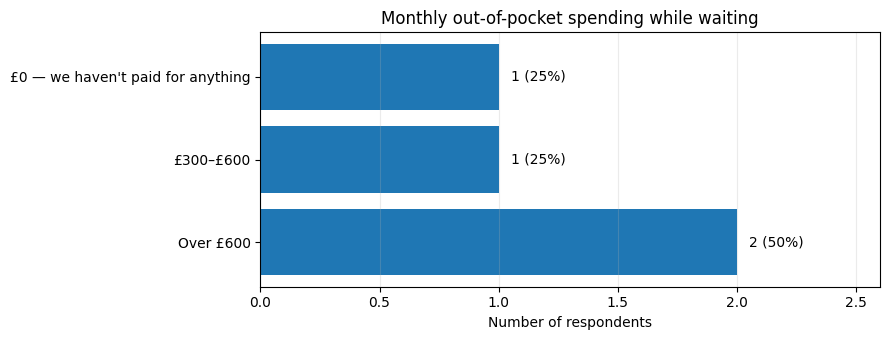

Reported any out-of-pocket spending: 3 of 4 (75.0%)
Spending bands are ordinal categories, so do not calculate a precise mean cost from them.


In [ ]:
SPEND_ORDER = [
    "£0 — we haven't paid for anything",
    "Less than £50", "£50–£100", "£100–£300", "£300–£600", "Over £600"
]
spend_table = frequency_table(df[COL["spend"]])
display(spend_table)
plot_frequency(
    df[COL["spend"]],
    "Monthly out-of-pocket spending while waiting",
    order=SPEND_ORDER,
    filename="out_of_pocket_spending.png"
)

valid_spend = df[COL["spend"]].dropna()
paid_any = (~valid_spend.str.startswith("£0", na=False)).sum()
if len(valid_spend):
    print(f"Reported any out-of-pocket spending: {paid_any} of {len(valid_spend)} ({paid_any/len(valid_spend)*100:.1f}%)")
print("Spending bands are ordinal categories, so do not calculate a precise mean cost from them.")

## 11. What would have made the biggest difference?

,Option,Count,Percent of valid respondents
0,Activities or exercises we could do at home in the meantime,4,100.0
1,Education on what SaLT actually involves and what to expect,3,75.0
2,Some form of professional contact during the wait,3,75.0
3,A way to track and document our child's communication progress,2,50.0
4,A community of other parents in the same situation,2,50.0
5,A clear estimate of when the wait would end,1,25.0


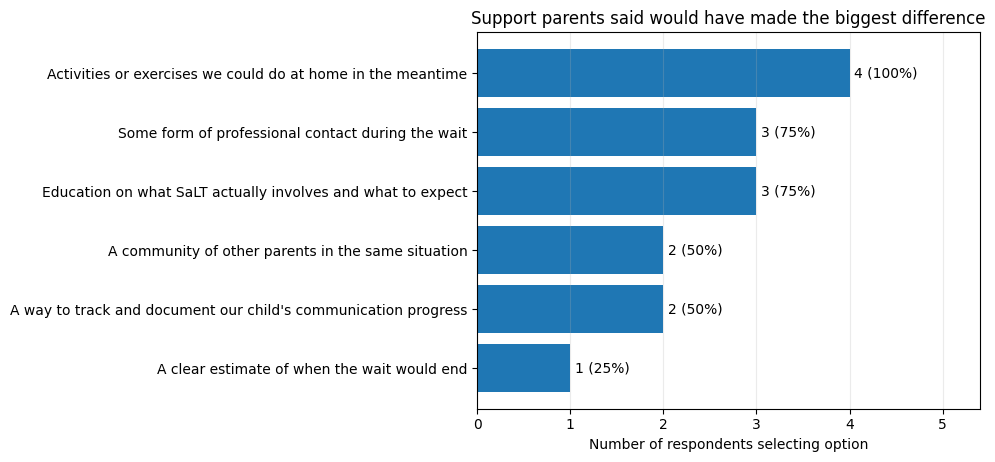

In [ ]:
difference_table = multiselect_table(df[COL["difference"]])
display(difference_table)
plot_multiselect(
    df[COL["difference"]],
    "Support parents said would have made the biggest difference",
    filename="biggest_difference.png"
)

## 12. Open-text responses and thematic analysis worksheet

In [ ]:
impact_responses = df.loc[
    df[COL["impact"]].notna(),
    ["Participant_ID", COL["impact"]]
].rename(columns={COL["impact"]: "Open_text_response"})

# Create blank coding columns for transparent manual thematic analysis
coding_sheet = impact_responses.copy()
coding_sheet["Initial_code_1"] = ""
coding_sheet["Initial_code_2"] = ""
coding_sheet["Candidate_theme"] = ""
coding_sheet["Analytic_note"] = ""
coding_sheet["Include_as_quote"] = ""



### Optional preliminary keyword scan

In [ ]:
# This is only a navigation aid, not a substitute for reflexive thematic analysis.
KEYWORD_GROUPS = {
    "Lack of support / left alone": ["no support", "solo", "left", "without support"],
    "Communication and child impact": ["communicat", "verbal", "speech", "language"],
    "Distress / behavioural impact": ["meltdown", "violence", "self harm", "worr"],
    "Education and participation": ["education", "school", "community", "function"],
    "Private payment / access": ["private", "pay", "paid", "funded", "cost"],
    "Assessment / EHCP": ["assessment", "ehcp"],
}

keyword_rows = []
for _, row in impact_responses.iterrows():
    text = row["Open_text_response"].lower()
    for theme, keywords in KEYWORD_GROUPS.items():
        if any(k in text for k in keywords):
            keyword_rows.append({"Participant_ID": row["Participant_ID"], "Preliminary_category": theme})

keyword_scan = pd.DataFrame(keyword_rows)
if keyword_scan.empty:
    print("No keyword matches found.")
else:
    display(keyword_scan)
    display(keyword_scan["Preliminary_category"].value_counts().rename_axis("Category").reset_index(name="Mentions"))

print("Do not report these automated categories as final themes without manual review.")

,Participant_ID,Preliminary_category
0,PW01,Lack of support / left alone
1,PW01,Communication and child impact
2,PW01,Distress / behavioural impact
3,PW02,Distress / behavioural impact
4,PW03,Private payment / access
5,PW03,Assessment / EHCP
6,PW04,Education and participation


,Category,Mentions
0,Distress / behavioural impact,2
1,Lack of support / left alone,1
2,Communication and child impact,1
3,Private payment / access,1
4,Assessment / EHCP,1
5,Education and participation,1


Do not report these automated categories as final themes without manual review.


## 13. Key descriptive findings generated automatically

In [ ]:
findings = []
findings.append(f"The analysed sample contained {N} parents/carers whose children were waiting for SaLT.")

valid_emotional = emotional.dropna()
if len(valid_emotional):
    unsupported = valid_emotional.isin(["Strongly disagree", "Disagree"]).sum()
    findings.append(
        f"{unsupported} of {len(valid_emotional)} respondents with valid data "
        f"({unsupported/len(valid_emotional)*100:.1f}%) disagreed or strongly disagreed that they felt emotionally supported."
    )

if not difference_table.empty:
    top_count = difference_table["Count"].max()
    top_options = difference_table.loc[difference_table["Count"] == top_count, "Option"].tolist()
    findings.append(
        f"The most frequently selected form(s) of desired support were: "
        + "; ".join(top_options)
        + f" ({int(top_count)} selection(s))."
    )

if len(valid_spend):
    findings.append(
        f"{paid_any} of {len(valid_spend)} respondents who answered the spending question reported some out-of-pocket expenditure."
    )

for item in findings:
    display(Markdown(f"- {item}"))

print("These statements are starting points. Check denominators and contextualise them with open-text findings before using them in the dissertation.")

NameError: name 'emotional' is not defined